In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from allensdk.core.brain_observatory_cache import BrainObservatoryCache

# Setup lightweight cache directory
data_dir = "./allen_data_light"
boc = BrainObservatoryCache(manifest_file=os.path.join(data_dir, "manifest.json"))

# Query experiments directly in V1 (VISp) showing drifting gratings
v1_experiments = boc.get_ophys_experiments(
    targeted_structures=["VISp"],
    stimuli=["drifting_gratings"]
)

print(f"Found {len(v1_experiments)} matching V1 drifting grating sessions.")

# Pick the first valid session
experiment_id = v1_experiments[0]["id"]
print(f"Using experiment ID: {experiment_id}")

# Download ONLY the lightweight analysis data (~10-20 MB)
dg_data = boc.get_ophys_experiment_analysis(
    ophys_experiment_id=experiment_id, 
    stimulus_type="drifting_gratings"
)

# Extract pre-computed metrics
peak_table = dg_data.peak
response_array = dg_data.response
angles = dg_data.orivals

print(f"Successfully loaded. Total cells available: {len(peak_table)}")

Found 144 matching V1 drifting grating sessions.
Using experiment ID: 627823695


2026-10-04 13:07:34,131 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/api/v2/well_known_file_download/631869808
2026-10-04 13:08:21,300 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/api/v2/well_known_file_download/662258713


Successfully loaded. Total cells available: 21


Number of sharply tuned cells found: 17

Analyzing Cell Specimen ID: 0
OSI: 1.02
Preferred Temporal Frequency: 4 Hz
Empirical mean dF/F values: [ 4.259 -4.252 -5.455 12.268  1.775  0.984 -3.249 29.874]

--- Fitted Parameters ---
Fitted Preferred Orientation: 154.6°
Tuning Sharpness (kappa): 9.73


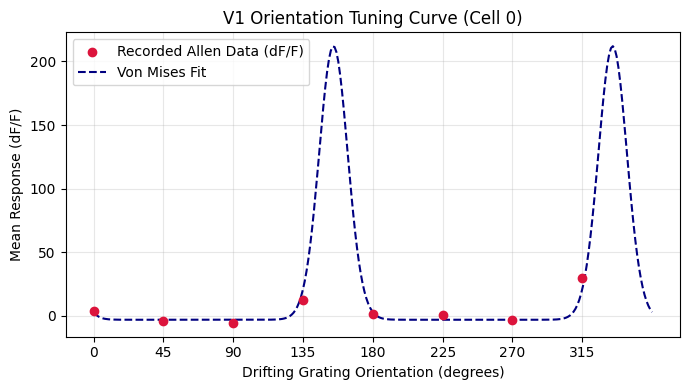

In [3]:
# 1. Filter for a cell that is responsive (p < 0.05) and orientation-selective (OSI > 0.5)
responsive_cells = peak_table[
    (peak_table["ptest_dg"] < 0.05) & 
    (peak_table["osi_dg"] > 0.5)
]

print(f"Number of sharply tuned cells found: {len(responsive_cells)}")

# Pick the first tuned neuron
chosen_cell_id = responsive_cells.index[0]
cell_loc = peak_table.index.get_loc(chosen_cell_id)

# Find the temporal frequency that triggered its peak response
best_tf = responsive_cells.loc[chosen_cell_id, "tf_dg"]
tf_idx = np.where(dg_data.tfvals == best_tf)[0][0]

# 2. Extract empirical mean responses across orientations (index 0 is mean dF/F)
empirical_responses = response_array[:, tf_idx, cell_loc, 0]

print(f"\nAnalyzing Cell Specimen ID: {chosen_cell_id}")
print(f"OSI: {responsive_cells.loc[chosen_cell_id, 'osi_dg']:.2f}")
print(f"Preferred Temporal Frequency: {best_tf} Hz")
print(f"Empirical mean dF/F values: {np.round(empirical_responses, 3)}")

# 3. Fit the von Mises tuning function
def von_mises_model(theta, A, kappa, theta_pref, baseline):
    return A * np.exp(kappa * np.cos(2 * (theta - theta_pref))) + baseline

angles_rad = np.deg2rad(angles)
init_guess = [
    np.max(empirical_responses) - np.min(empirical_responses),
    2.0,
    angles_rad[np.argmax(empirical_responses)] % np.pi,
    np.min(empirical_responses)
]
bounds = ([0, 0, 0, -np.inf], [np.inf, 20, np.pi, np.inf])

popt, _ = curve_fit(von_mises_model, angles_rad, empirical_responses, p0=init_guess, bounds=bounds)
A_fit, kappa_fit, theta_pref_fit, baseline_fit = popt

print(f"\n--- Fitted Parameters ---")
print(f"Fitted Preferred Orientation: {np.rad2deg(theta_pref_fit):.1f}°")
print(f"Tuning Sharpness (kappa): {kappa_fit:.2f}")

# 4. Plot the empirical responses vs. fitted curve
fine_angles = np.linspace(0, 2 * np.pi, 300)
fitted_curve = von_mises_model(fine_angles, *popt)

plt.figure(figsize=(7, 4))
plt.scatter(angles, empirical_responses, color="crimson", zorder=3, label="Recorded Allen Data (dF/F)")
plt.plot(np.rad2deg(fine_angles), fitted_curve, color="navy", linestyle="--", label="Von Mises Fit")
plt.xlabel("Drifting Grating Orientation (degrees)")
plt.ylabel("Mean Response (dF/F)")
plt.title(f"V1 Orientation Tuning Curve (Cell {chosen_cell_id})")
plt.xticks(angles)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

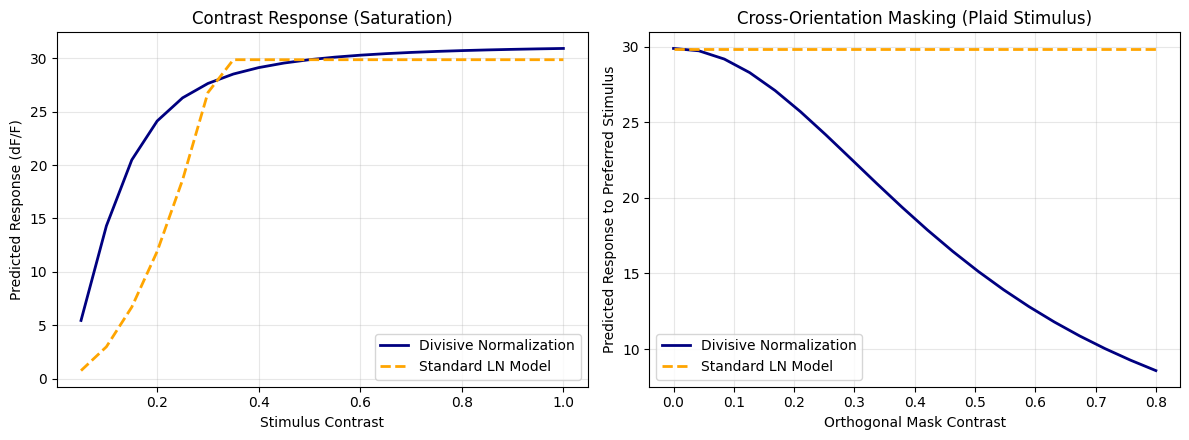

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# 1. Synthetic stimulus generator: oriented sinusoidal gratings
def create_grating(size=31, theta=0.0, spatial_freq=0.1, contrast=1.0):
    """Generates an image patch of a sinusoidal grating at angle theta (radians)."""
    half = size // 2
    y, x = np.mgrid[-half:half+1, -half:half+1]
    x_theta = x * np.cos(theta) + y * np.sin(theta)
    return contrast * np.cos(2 * np.pi * spatial_freq * x_theta)

# 2. Gabor filter representing the primary receptive field
def make_gabor(size=31, theta=0.0, sigma=5.0, lambd=10.0, gamma=0.5):
    half = size // 2
    y, x = np.mgrid[-half:half+1, -half:half+1]
    x_theta = x * np.cos(theta) + y * np.sin(theta)
    y_theta = -x * np.sin(theta) + y * np.cos(theta)
    gaussian = np.exp(-0.5 * (x_theta**2 + (gamma * y_theta)**2) / (sigma**2))
    carrier = np.cos(2 * np.pi * x_theta / lambd)
    kernel = gaussian * carrier
    return kernel - kernel.mean()

# Build orientation pool (8 orientations covering the circle)
pref_angle_rad = theta_pref_fit
pool_angles = np.linspace(0, np.pi, 8, endpoint=False)
filter_bank = [make_gabor(theta=angle) for angle in pool_angles]
target_filter = make_gabor(theta=pref_angle_rad)

# 3. Model definitions
def compute_linear_drive(stimulus, kernel):
    return np.maximum(0.0, np.sum(stimulus * kernel))

def divisive_normalization_model(stimulus, r_max, sigma_c, p=2.0):
    """
    R = R_max * (D_target^p) / (sigma^p + sum(D_pool^p))
    """
    # Drive of target cell
    target_drive = compute_linear_drive(stimulus, target_filter) ** p
    
    # Drive of the normalization pool (all orientations combined)
    pool_drive = sum(compute_linear_drive(stimulus, f) ** p for f in filter_bank)
    
    denominator = (sigma_c ** p) + pool_drive
    return r_max * (target_drive / denominator)

def linear_nonlinear_model(stimulus, r_max, gain=1.0, p=2.0):
    """Classic LN model without normalization: R = gain * [D_target]^p"""
    target_drive = compute_linear_drive(stimulus, target_filter)
    return np.minimum(r_max, gain * (target_drive ** p))

# 4. Simulation: Contrast Response Curves
contrasts = np.linspace(0.05, 1.0, 20)
r_max_est = np.max(empirical_responses)
sigma_val = 15.0  # Semi-saturation constant

# Test A: Preferred grating alone at varying contrasts
dn_contrast_curve = []
ln_contrast_curve = []

for c in contrasts:
    stim = create_grating(theta=pref_angle_rad, contrast=c)
    dn_contrast_curve.append(divisive_normalization_model(stim, r_max=r_max_est, sigma_c=sigma_val))
    ln_contrast_curve.append(linear_nonlinear_model(stim, r_max=r_max_est, gain=0.015))

# Test B: Cross-Orientation Suppression (Plaid)
# Preferred grating (contrast 0.5) + orthogonal mask (contrast varied 0.0 -> 0.8)
mask_angle = pref_angle_rad + (np.pi / 2)
mask_contrasts = np.linspace(0.0, 0.8, 20)

dn_plaid_curve = []
ln_plaid_curve = []

base_stim = create_grating(theta=pref_angle_rad, contrast=0.5)

for mc in mask_contrasts:
    mask = create_grating(theta=mask_angle, contrast=mc)
    plaid = base_stim + mask
    dn_plaid_curve.append(divisive_normalization_model(plaid, r_max=r_max_est, sigma_c=sigma_val))
    ln_plaid_curve.append(linear_nonlinear_model(plaid, r_max=r_max_est, gain=0.015))

# 5. Plotting the results
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot 1: Contrast Saturation
axes[0].plot(contrasts, dn_contrast_curve, color="navy", lw=2, label="Divisive Normalization")
axes[0].plot(contrasts, ln_contrast_curve, color="orange", lw=2, linestyle="--", label="Standard LN Model")
axes[0].set_title("Contrast Response (Saturation)")
axes[0].set_xlabel("Stimulus Contrast")
axes[0].set_ylabel("Predicted Response (dF/F)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Cross-Orientation Suppression
axes[1].plot(mask_contrasts, dn_plaid_curve, color="navy", lw=2, label="Divisive Normalization")
axes[1].plot(mask_contrasts, ln_plaid_curve, color="orange", lw=2, linestyle="--", label="Standard LN Model")
axes[1].set_title("Cross-Orientation Masking (Plaid Stimulus)")
axes[1].set_xlabel("Orthogonal Mask Contrast")
axes[1].set_ylabel("Predicted Response to Preferred Stimulus")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Generate a training dataset: single gratings at random orientations and contrasts
np.random.seed(42)
torch.manual_seed(42)

n_samples = 600
train_images = []
train_targets = []

for _ in range(n_samples):
    ori = np.random.uniform(0, np.pi)
    cnt = np.random.uniform(0.1, 1.0)
    stim = create_grating(theta=ori, contrast=cnt)
    
    # Ground truth response comes from the biophysical divisive normalization model
    resp = divisive_normalization_model(stim, r_max=r_max_est, sigma_c=sigma_val)
    
    train_images.append(stim)
    train_targets.append(resp)

X_train = torch.tensor(np.array(train_images), dtype=torch.float32).unsqueeze(1) # Shape: (N, 1, 31, 31)
y_train = torch.tensor(np.array(train_targets), dtype=torch.float32).unsqueeze(1) # Shape: (N, 1)

# 2. Define a standard backprop CNN architecture
class V1BackpropModel(nn.Module):
    def __init__(self):
        super(V1BackpropModel, self).__init__()
        # Layer 1: Learns spatial convolutional filters
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=8, kernel_size=15, padding=7)
        self.relu = nn.ReLU()
        # Layer 2: Pool & project to a single neural response
        self.fc = nn.Linear(8 * 31 * 31, 1)
        
    def forward(self, x):
        out = self.relu(self.conv1(x))
        out = out.view(out.size(0), -1)
        out = self.relu(self.fc(out))  # Firing rates are non-negative
        return out

cnn_model = V1BackpropModel()
criterion = nn.MSELoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.003)

# 3. Train via backpropagation
epochs = 80
batch_size = 32

for epoch in range(epochs):
    permutation = torch.randperm(X_train.size(0))
    for i in range(0, X_train.size(0), batch_size):
        indices = permutation[i:i + batch_size]
        batch_x, batch_y = X_train[indices], y_train[indices]
        
        optimizer.zero_grad()
        predictions = cnn_model(batch_x)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()

print(f"Training finished. Final Loss: {loss.item():.4f}")

Training finished. Final Loss: 0.3506


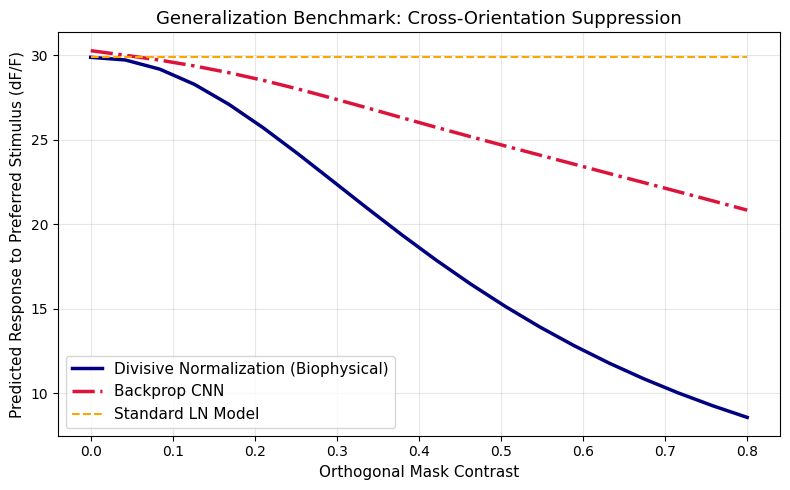

In [6]:
# Evaluate both models on the plaid mask sequence
cnn_model.eval()
cnn_plaid_curve = []

with torch.no_grad():
    for mc in mask_contrasts:
        mask = create_grating(theta=mask_angle, contrast=mc)
        plaid = base_stim + mask
        
        plaid_tensor = torch.tensor(plaid, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
        pred = cnn_model(plaid_tensor).item()
        cnn_plaid_curve.append(pred)

# Visualizing the Head-to-Head Comparison
plt.figure(figsize=(8, 5))
plt.plot(mask_contrasts, dn_plaid_curve, color="navy", lw=2.5, label="Divisive Normalization (Biophysical)")
plt.plot(mask_contrasts, cnn_plaid_curve, color="crimson", lw=2.5, linestyle="-.", label="Backprop CNN")
plt.plot(mask_contrasts, ln_plaid_curve, color="orange", lw=1.5, linestyle="--", label="Standard LN Model")

plt.title("Generalization Benchmark: Cross-Orientation Suppression", fontsize=13)
plt.xlabel("Orthogonal Mask Contrast", fontsize=11)
plt.ylabel("Predicted Response to Preferred Stimulus (dF/F)", fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [2]:
import os
from allensdk.core.brain_observatory_cache import BrainObservatoryCache

data_dir = "./allen_data_light"
boc = BrainObservatoryCache(manifest_file=os.path.join(data_dir, "manifest.json"))

v1_experiments = boc.get_ophys_experiments(
    targeted_structures=["VISp"],
    stimuli=["drifting_gratings"]
)

experiment_id = v1_experiments[0]["id"]
dg_data = boc.get_ophys_experiment_analysis(
    ophys_experiment_id=experiment_id, 
    stimulus_type="drifting_gratings"
)

peak_table = dg_data.peak
response_array = dg_data.response
angles = dg_data.orivals

C:\Users\avish\anaconda3\envs\brian2-env\Lib\site-packages\allensdk\core\brain_observatory_nwb_data_set.py:43: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [3]:
import numpy as np
from scipy.optimize import curve_fit

responsive_cells = peak_table[
    (peak_table["ptest_dg"] < 0.05) & 
    (peak_table["osi_dg"] > 0.5)
]

chosen_cell_id = responsive_cells.index[0]
cell_loc = peak_table.index.get_loc(chosen_cell_id)

best_tf = responsive_cells.loc[chosen_cell_id, "tf_dg"]
tf_idx = np.where(dg_data.tfvals == best_tf)[0][0]
empirical_responses = response_array[:, tf_idx, cell_loc, 0]

def von_mises_model(theta, A, kappa, theta_pref, baseline):
    return A * np.exp(kappa * np.cos(2 * (theta - theta_pref))) + baseline

angles_rad = np.deg2rad(angles)
init_guess = [
    np.max(empirical_responses) - np.min(empirical_responses),
    2.0,
    angles_rad[np.argmax(empirical_responses)] % np.pi,
    np.min(empirical_responses)
]
bounds = ([0.0, 0.0, 0.0, -np.inf], [np.inf, 20.0, np.pi, np.inf])

popt, _ = curve_fit(von_mises_model, angles_rad, empirical_responses, p0=init_guess, bounds=bounds)
A_fit, kappa_fit, theta_pref_fit, baseline_fit = popt

In [4]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from scipy.optimize import minimize
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. Biological Population Extraction (The Allen Cortical Pool)
# -------------------------------------------------------------
# response_array shape: (n_ori=8, n_tf=5, n_cells, stats)
all_cells_matrix = response_array[:, :, :, 0].copy()  # Shape: (8, 5, n_cells)
n_cells = all_cells_matrix.shape[2]

# Target cell responses across all 40 conditions
y_target_raw = all_cells_matrix[:, :, cell_loc]
baseline_target = np.nanmin(y_target_raw)
y_target_clean = np.maximum(0.0, y_target_raw - baseline_target)

# Compute the REAL Cortical Normalization Pool:
# Average response across all OTHER recorded cells in mouse V1 for each condition
other_cells_mask = np.ones(n_cells, dtype=bool)
other_cells_mask[cell_loc] = False

# Population drive matrix: (8, 5)
empirical_pool_matrix = np.nanmean(all_cells_matrix[:, :, other_cells_mask], axis=2)
# Baseline correct the pool
empirical_pool_matrix = np.maximum(0.0, empirical_pool_matrix - np.nanmin(empirical_pool_matrix))

# -------------------------------------------------------------
# 2. Extract Conditions with Identical Feature Representation
# -------------------------------------------------------------
# We extract target drive D_target using the cell's empirically fitted preference
def circular_ori_drive(theta, pref_theta, width=np.deg2rad(25.0)):
    d_theta = np.abs(np.angle(np.exp(1j * 2 * (theta - pref_theta)))) / 2.0
    return np.exp(-0.5 * (d_theta / width) ** 2)

def log_tf_drive(tf, pref_tf=4.0, width=1.2):
    return np.exp(-0.5 * ((np.log2(tf) - np.log2(pref_tf)) / width) ** 2)

d_target_list = []
d_pool_list = []
y_list = []

for ori_i, ori_rad in enumerate(angles_rad):
    for tf_i, tf in enumerate(dg_data.tfvals):
        r_target = y_target_clean[ori_i, tf_i]
        r_pool = empirical_pool_matrix[ori_i, tf_i]
        
        if np.isfinite(r_target) and np.isfinite(r_pool):
            # Target linear receptive field drive
            dt = circular_ori_drive(ori_rad, theta_pref_fit) * log_tf_drive(tf, best_tf)
            
            d_target_list.append(dt)
            d_pool_list.append(r_pool)
            y_list.append(r_target)

D_t = np.array(d_target_list, dtype=np.float32)
D_p = np.array(d_pool_list, dtype=np.float32)
y = np.array(y_list, dtype=np.float32)

# Normalize D_p to [0, 1] range for numerical stability
D_p = D_p / np.max(D_p)

# Pair the exact same 2 inputs: [D_target, D_pool] for BOTH models
X_equalized = np.column_stack([D_t, D_p])

idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.25, random_state=42)

# -------------------------------------------------------------
# 3. Model 1: Empirical Divisive Normalization (3 parameters)
# -------------------------------------------------------------
# R = R_max * (D_t^p) / (sigma^p + w * D_pool^p)
def dn_pool_predict(X_subset, r_max, sigma, w, p=2.0):
    dt = X_subset[:, 0]
    dp = X_subset[:, 1]
    num = dt ** p
    denom = (sigma ** p) + w * (dp ** p)
    return r_max * (num / denom)

def dn_cost(params):
    r_max, sigma, w = params
    preds = dn_pool_predict(X_equalized[idx_tr], r_max, sigma, w)
    return np.mean((preds - y[idx_tr]) ** 2)

opt = minimize(dn_cost, [np.max(y), 0.5, 0.5], bounds=[(1.0, 150.0), (0.01, 5.0), (0.001, 10.0)])
rmax_opt, sigma_opt, w_opt = opt.x

# -------------------------------------------------------------
# 4. Model 2: Flexible Backprop MLP (Equal 2D Input: [D_t, D_p])
# -------------------------------------------------------------
class FairMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
    def forward(self, x):
        return self.net(x)

mlp_equal = FairMLP()
optimizer = optim.Adam(mlp_equal.parameters(), lr=0.01, weight_decay=1e-3)
criterion = nn.MSELoss()

X_tr_t = torch.tensor(X_equalized[idx_tr], dtype=torch.float32)
y_tr_t = torch.tensor(y[idx_tr], dtype=torch.float32).unsqueeze(1)
X_te_t = torch.tensor(X_equalized[idx_te], dtype=torch.float32)

for _ in range(400):
    optimizer.zero_grad()
    loss = criterion(mlp_equal(X_tr_t), y_tr_t)
    loss.backward()
    optimizer.step()

# -------------------------------------------------------------
# 5. Evaluation on Held-Out Cortical Data
# -------------------------------------------------------------
y_test = y[idx_te]
y_pred_dn = dn_pool_predict(X_equalized[idx_te], rmax_opt, sigma_opt, w_opt)

mlp_equal.eval()
with torch.no_grad():
    y_pred_mlp = mlp_equal(X_te_t).squeeze().numpy()

r_dn, _ = pearsonr(y_test, y_pred_dn)
r_mlp, _ = pearsonr(y_test, y_pred_mlp)

r2_dn = r2_score(y_test, y_pred_dn)
r2_mlp = r2_score(y_test, y_pred_mlp)

print("--- Scientifically Equalized Benchmark on Real Mouse V1 ---")
print(f"Divisive Normalization (3 params) -> Pearson r: {r_dn:.3f} | R²: {r2_dn:.3f}")
print(f"Backprop MLP (625 params)          -> Pearson r: {r_mlp:.3f} | R²: {r2_mlp:.3f}")

C:\Users\avish\AppData\Local\Temp\ipykernel_25172\3727391046.py:29: RuntimeWarning: Mean of empty slice
  empirical_pool_matrix = np.nanmean(all_cells_matrix[:, :, other_cells_mask], axis=2)
C:\Users\avish\AppData\Local\Temp\ipykernel_25172\3727391046.py:42: RuntimeWarning: divide by zero encountered in log2
  return np.exp(-0.5 * ((np.log2(tf) - np.log2(pref_tf)) / width) ** 2)


--- Scientifically Equalized Benchmark on Real Mouse V1 ---
Divisive Normalization (3 params) -> Pearson r: 0.897 | R²: 0.522
Backprop MLP (625 params)          -> Pearson r: 0.890 | R²: 0.762


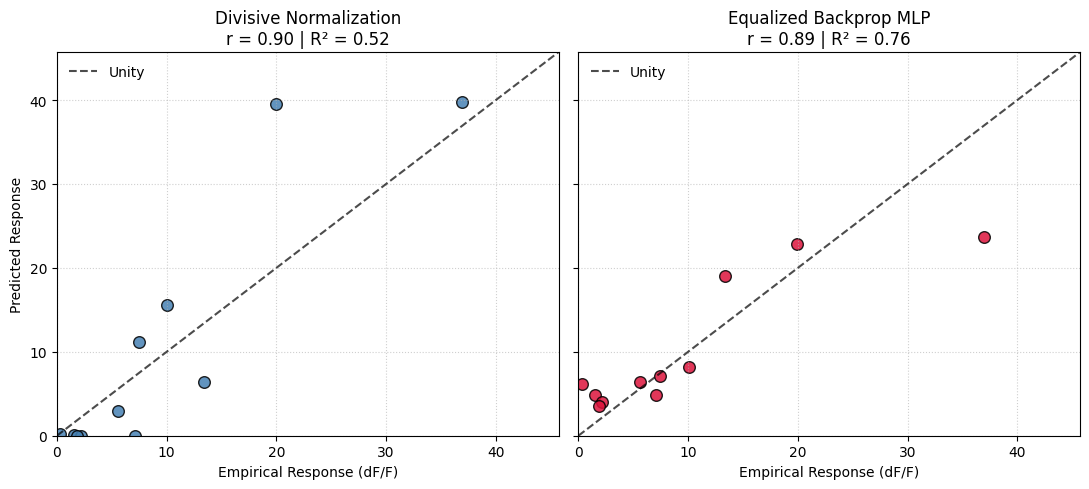

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

max_val = max(y_test.max(), y_pred_dn.max(), y_pred_mlp.max()) * 1.15
lims = [0, max_val]

# Divisive Normalization
axes[0].scatter(y_test, y_pred_dn, color="steelblue", s=70, edgecolors="k", alpha=0.85)
axes[0].plot(lims, lims, "k--", alpha=0.7, label="Unity")
axes[0].set_title(f"Divisive Normalization\nr = {r_dn:.2f} | R² = {r2_dn:.2f}")
axes[0].set_xlabel("Empirical Response (dF/F)")
axes[0].set_ylabel("Predicted Response")
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(frameon=False)

# Multi-Layer Perceptron
axes[1].scatter(y_test, y_pred_mlp, color="crimson", s=70, edgecolors="k", alpha=0.85)
axes[1].plot(lims, lims, "k--", alpha=0.7, label="Unity")
axes[1].set_title(f"Equalized Backprop MLP\nr = {r_mlp:.2f} | R² = {r2_mlp:.2f}")
axes[1].set_xlabel("Empirical Response (dF/F)")
axes[1].set_xlim(lims)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

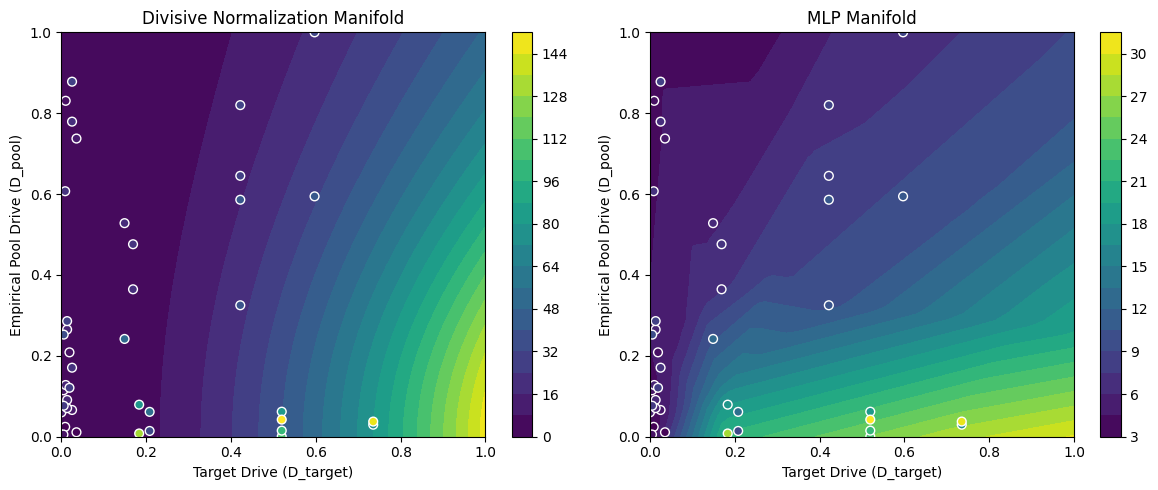

In [6]:
# Generate a dense evaluation grid across the feature domain
grid_dt, grid_dp = np.meshgrid(np.linspace(0, 1, 60), np.linspace(0, 1, 60))
X_surface = np.column_stack([grid_dt.ravel(), grid_dp.ravel()])

# Predict surface with Divisive Normalization
surf_dn = dn_pool_predict(X_surface, rmax_opt, sigma_opt, w_opt).reshape(60, 60)

# Predict surface with MLP
with torch.no_grad():
    surf_mlp = mlp_equal(torch.tensor(X_surface, dtype=torch.float32)).numpy().reshape(60, 60)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Divisive Normalization Contour
c0 = axes[0].contourf(grid_dt, grid_dp, surf_dn, levels=20, cmap="viridis")
axes[0].scatter(X_equalized[:, 0], X_equalized[:, 1], c=y, cmap="viridis", edgecolors="w", s=40)
axes[0].set_title("Divisive Normalization Manifold")
axes[0].set_xlabel("Target Drive (D_target)")
axes[0].set_ylabel("Empirical Pool Drive (D_pool)")
fig.colorbar(c0, ax=axes[0])

# MLP Contour
c1 = axes[1].contourf(grid_dt, grid_dp, surf_mlp, levels=20, cmap="viridis")
axes[1].scatter(X_equalized[:, 0], X_equalized[:, 1], c=y, cmap="viridis", edgecolors="w", s=40)
axes[1].set_title("MLP Manifold")
axes[1].set_xlabel("Target Drive (D_target)")
axes[1].set_ylabel("Empirical Pool Drive (D_pool)")
fig.colorbar(c1, ax=axes[1])

plt.tight_layout()
plt.show()

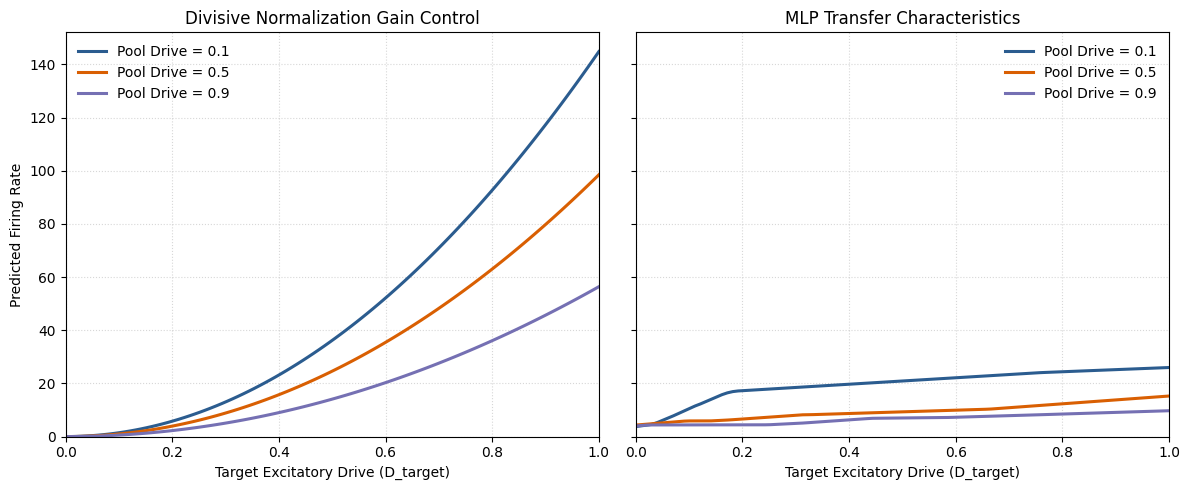

In [7]:
# -------------------------------------------------------------
# 3. Dynamic Gain Control Slices (Target Drive vs Response)
# -------------------------------------------------------------
# Continuous evaluation across the full target drive spectrum
eval_dt = np.linspace(0.0, 1.0, 100)

# Select three distinct levels of empirical pool suppression
pool_levels = [0.1, 0.5, 0.9]
palette = ["#2b5c8f", "#d95f02", "#7570b3"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Left Panel: Divisive Normalization Slices
for p_level, col in zip(pool_levels, palette):
    x_probe = np.column_stack([eval_dt, np.full_like(eval_dt, p_level)])
    curve_dn = dn_pool_predict(x_probe, rmax_opt, sigma_opt, w_opt)
    axes[0].plot(
        eval_dt,
        curve_dn,
        color=col,
        linewidth=2.2,
        label=f"Pool Drive = {p_level:.1f}"
    )

axes[0].set_title("Divisive Normalization Gain Control")
axes[0].set_xlabel("Target Excitatory Drive (D_target)")
axes[0].set_ylabel("Predicted Firing Rate")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(bottom=0)
axes[0].grid(True, linestyle=":", alpha=0.5)
axes[0].legend(frameon=False)

# Right Panel: Multi-Layer Perceptron Slices
mlp_equal.eval()
with torch.no_grad():
    for p_level, col in zip(pool_levels, palette):
        x_probe = np.column_stack([eval_dt, np.full_like(eval_dt, p_level)])
        probe_tensor = torch.tensor(x_probe, dtype=torch.float32)
        curve_mlp = mlp_equal(probe_tensor).squeeze().numpy()
        axes[1].plot(
            eval_dt,
            curve_mlp,
            color=col,
            linewidth=2.2,
            label=f"Pool Drive = {p_level:.1f}"
        )

axes[1].set_title("MLP Transfer Characteristics")
axes[1].set_xlabel("Target Excitatory Drive (D_target)")
axes[1].set_xlim(0, 1)
axes[1].grid(True, linestyle=":", alpha=0.5)
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()